In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (1460, 81)
Number of Rows: 1460
Number of Columns: 81


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
print(df.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [6]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [7]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]
print("Columns with Missing Values:")
print(missing_values.sort_values(ascending=False))

Columns with Missing Values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})
missing_df = missing_df[missing_df['Missing Values'] > 0]
missing_df = missing_df.sort_values(
    by='Missing Percentage',
    ascending=False
)
missing_df

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [10]:
print("Average House Price:", df['SalePrice'].mean())
print("Median House Price:", df['SalePrice'].median())
print("Minimum House Price:", df['SalePrice'].min())
print("Maximum House Price:", df['SalePrice'].max())
print("Standard Deviation:", df['SalePrice'].std())

Average House Price: 180921.19589041095
Median House Price: 163000.0
Minimum House Price: 34900
Maximum House Price: 755000
Standard Deviation: 79442.50288288662


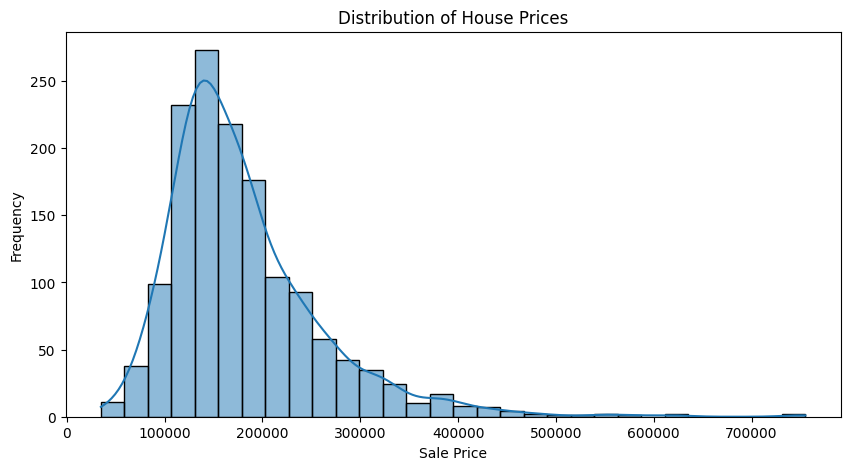

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(
    df['SalePrice'],
    bins=30,
    kde=True
)
plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

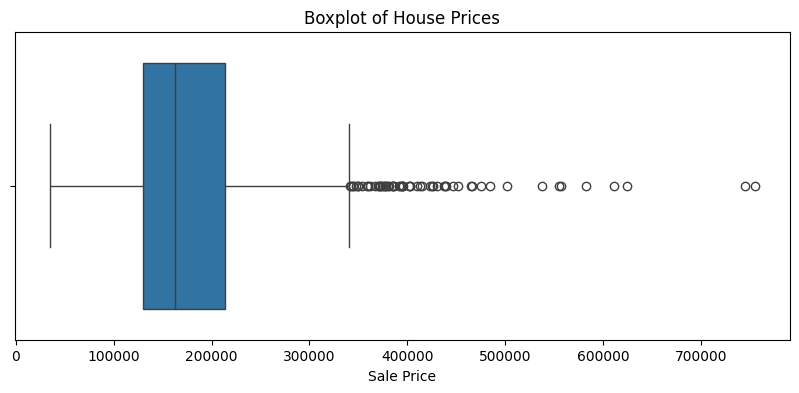

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['SalePrice'])
plt.title('Boxplot of House Prices')
plt.xlabel('Sale Price')
plt.show()

In [13]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns
categorical_columns = df.select_dtypes(
    include=['object']
).columns
print("Numerical Columns:", len(numerical_columns))
print("Categorical Columns:", len(categorical_columns))
print("\nCategorical Features:")
print(categorical_columns.tolist())

Numerical Columns: 38
Categorical Columns: 43

Categorical Features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


## Feature Selection Discussion

Feature selection is the process of identifying the most relevant
independent variables for predicting the target variable.

In this project, SalePrice is our target variable.

We consider the following features:

1. OverallQual – Overall quality of the house.
2. GrLivArea – Above-ground living area.
3. TotalBsmtSF – Total basement area.
4. GarageCars – Garage capacity.
5. YearBuilt – Year of construction.
6. FullBath – Number of full bathrooms.
7. BedroomAbvGr – Number of bedrooms.
8. LotArea – Total land area.
9. Neighborhood – Location of the house.

These features may influence the market value of a property.

We will use exploratory data analysis and correlation analysis
to understand their relationship with SalePrice.

In [14]:
selected_features = [
    'OverallQual',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageCars',
    'YearBuilt',
    'FullBath',
    'BedroomAbvGr',
    'LotArea',
    'Neighborhood'
]
X = df[selected_features]
y = df['SalePrice']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1460, 9)
Target Shape: (1460,)


In [15]:
X.head()

,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt,FullBath,BedroomAbvGr,LotArea,Neighborhood
0,7,1710,856,2,2003,2,3,8450,CollgCr
1,6,1262,1262,2,1976,2,3,9600,Veenker
2,7,1786,920,2,2001,2,3,11250,CollgCr
3,7,1717,756,3,1915,1,3,9550,Crawfor
4,8,2198,1145,3,2000,2,4,14260,NoRidge


In [16]:
y.head()

0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

## Feature Selection Discussion

Feature selection is the process of identifying the most relevant
independent variables for predicting the target variable.

In this project, SalePrice is our target variable.

We consider the following features:

1. OverallQual – Overall quality of the house.
2. GrLivArea – Above-ground living area.
3. TotalBsmtSF – Total basement area.
4. GarageCars – Garage capacity.
5. YearBuilt – Year of construction.
6. FullBath – Number of full bathrooms.
7. BedroomAbvGr – Number of bedrooms.
8. LotArea – Total land area.
9. Neighborhood – Location of the house.

These features may influence the market value of a property.

We will use exploratory data analysis and correlation analysis
to understand their relationship with SalePrice.

In [17]:
selected_features = [
    'OverallQual',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageCars',
    'YearBuilt',
    'FullBath',
    'BedroomAbvGr',
    'LotArea',
    'Neighborhood'
]
X = df[selected_features]
y = df['SalePrice']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1460, 9)
Target Shape: (1460,)


In [18]:
X.head()

,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt,FullBath,BedroomAbvGr,LotArea,Neighborhood
0,7,1710,856,2,2003,2,3,8450,CollgCr
1,6,1262,1262,2,1976,2,3,9600,Veenker
2,7,1786,920,2,2001,2,3,11250,CollgCr
3,7,1717,756,3,1915,1,3,9550,Crawfor
4,8,2198,1145,3,2000,2,4,14260,NoRidge


In [19]:
y.head()

0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

In [20]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)
print("\nCategorical Features:")
print(categorical_features

Numerical Features:
['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea']

Categorical Features:
['Neighborhood']


In [21]:
print("Missing values in numerical features:")
print(X[numerical_features].isnull().sum())

print("\nMissing values in categorical features:")
print(X[categorical_features].isnull().sum())

Missing values in numerical features:
OverallQual     0
GrLivArea       0
TotalBsmtSF     0
GarageCars      0
YearBuilt       0
FullBath        0
BedroomAbvGr    0
LotArea         0
dtype: int64

Missing values in categorical features:
Neighborhood    0
dtype: int64


In [22]:
numerical_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')
print("Imputers created successfully!")

Imputers created successfully!


In [23]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)
print("One-Hot Encoder created successfully!")

One-Hot Encoder created successfully!


In [24]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])
print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [25]:
X_processed = preprocessor.fit_transform(X)
print("Original Dataset Shape:", X.shape)
print("Processed Dataset Shape:", X_processed.shape)

Original Dataset Shape: (1460, 9)
Processed Dataset Shape: (1460, 33)


In [27]:
print("Data Type:", type(X_processed))
print("Processed Shape:", X_processed.shape)

Data Type: <class 'scipy.sparse._csr.csr_matrix'>
Processed Shape: (1460, 33)


In [28]:
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()
print("Converted Data Type:", type(X_processed))
print("Processed Shape:", X_processed.shape)

Converted Data Type: <class 'numpy.ndarray'>
Processed Shape: (1460, 33)


In [29]:
print("Missing values after preprocessing:",
      np.isnan(X_processed).sum())
print("Processed data shape:", X_processed.shape)
print("Preprocessing completed successfully!")

Missing values after preprocessing: 0
Processed data shape: (1460, 33)
Preprocessing completed successfully!


In [30]:
correlation_data = df[
    numerical_features + ['SalePrice']
]
correlation_matrix = correlation_data.corr()

price_correlation = correlation_matrix['SalePrice'].sort_values(
    ascending=False
)
print("Correlation with House Prices:")
print(price_correlation)

Correlation with House Prices:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
TotalBsmtSF     0.613581
FullBath        0.560664
YearBuilt       0.522897
LotArea         0.263843
BedroomAbvGr    0.168213
Name: SalePrice, dtype: float64


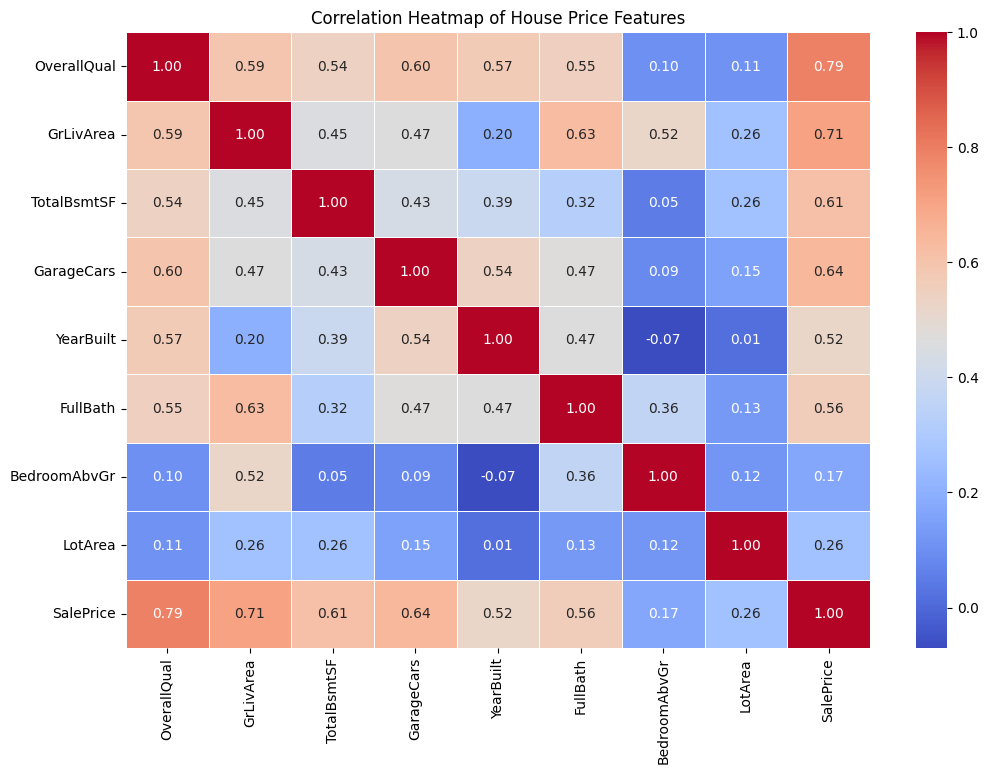

In [31]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of House Price Features')
plt.show()

In [32]:
top_correlations = price_correlation.drop(
    'SalePrice'
).abs().sort_values(ascending=False).head(5)
print("Top 5 Features Related to House Prices:")
print(top_correlations)

Top 5 Features Related to House Prices:
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
TotalBsmtSF    0.613581
FullBath       0.560664
Name: SalePrice, dtype: float64


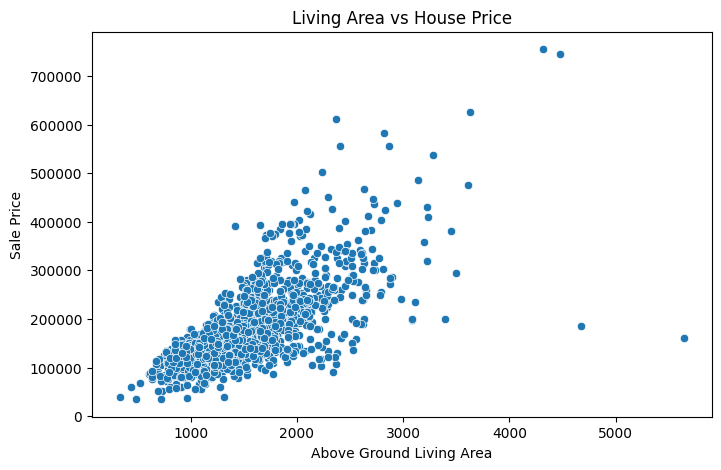

In [33]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice'
)
plt.title('Living Area vs House Price')
plt.xlabel('Above Ground Living Area')
plt.ylabel('Sale Price')
plt.show()

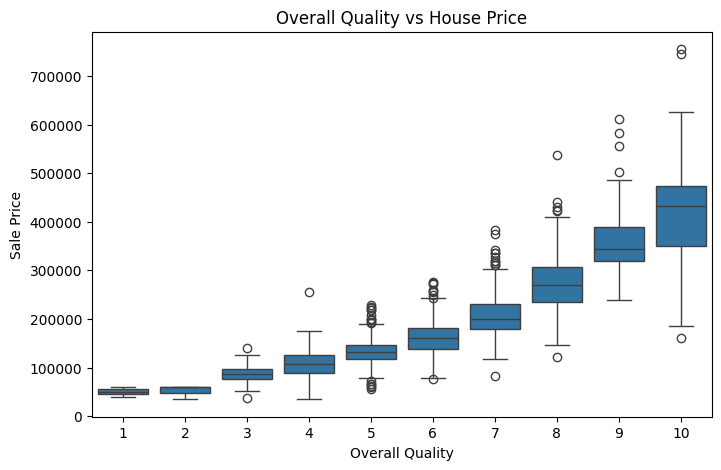

In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='OverallQual',
    y='SalePrice'
)
plt.title('Overall Quality vs House Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')
plt.show()

## Correlation Analysis

Correlation analysis helps identify relationships between
independent variables and the target variable SalePrice.

GrLivArea and OverallQual are expected to show strong
positive relationships with SalePrice.

This indicates that larger living areas and higher-quality
houses generally have higher selling prices.

Other features such as GarageCars, TotalBsmtSF and YearBuilt
may also influence house prices.

Correlation does not necessarily imply causation.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (1168, 9)
Testing Features Shape: (292, 9)
Training Target Shape: (1168,)
Testing Target Shape: (292,)


In [36]:
print("Total Records:", len(X))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Training Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")
print("Testing Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Total Records: 1460
Training Records: 1168
Testing Records: 292
Training Percentage: 80.0 %
Testing Percentage: 20.0 %


In [37]:
linear_model = LinearRegression()
print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [38]:
model_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])
print("Machine Learning pipeline created successfully!")

Machine Learning pipeline created successfully!


In [39]:
model_pipeline.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [40]:
y_pred = model_pipeline.predict(X_test)
print("Predictions generated successfully!")
print("\nFirst 10 Predicted House Prices:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Predicted House Prices:
[136974.35899257 328961.59596644 117585.6114433  179363.27866741
 274674.33050757  71810.61741812 233215.56620582 163888.73428819
  71308.22920834 125882.59796275]


In [41]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
comparison.head(10)

,Actual Price,Predicted Price
0,154500,136974.358993
1,325000,328961.595966
2,115000,117585.611443
3,159000,179363.278667
4,315500,274674.330508
5,75500,71810.617418
6,311500,233215.566206
7,146000,163888.734288
8,84500,71308.229208
9,135500,125882.597963


In [42]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 1293987708.4568377


In [43]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 35972.04064904906


In [44]:
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.831299520580446


In [45]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

Mean Absolute Error: 21888.53960587069


In [46]:
evaluation_results = pd.DataFrame({
    'Metric': ['MSE', 'RMSE', 'MAE', 'R2 Score'],
    'Value': [mse, rmse, mae, r2]
})
evaluation_results

,Metric,Value
0,MSE,1.293988e+09
1,RMSE,3.597204e+04
2,MAE,2.188854e+04
3,R2 Score,8.312995e-01


## Model Evaluation

The Linear Regression model was evaluated using four metrics:

1. MSE measures the average squared prediction error.
2. RMSE measures prediction error in the original price unit.
3. MAE measures the average absolute prediction error.
4. R2 Score measures the proportion of variance explained by the model.

A lower MSE, RMSE and MAE indicate better predictions,
while a higher R2 Score indicates better explanatory performance.

These metrics help us understand the accuracy and limitations
of our house price prediction model.

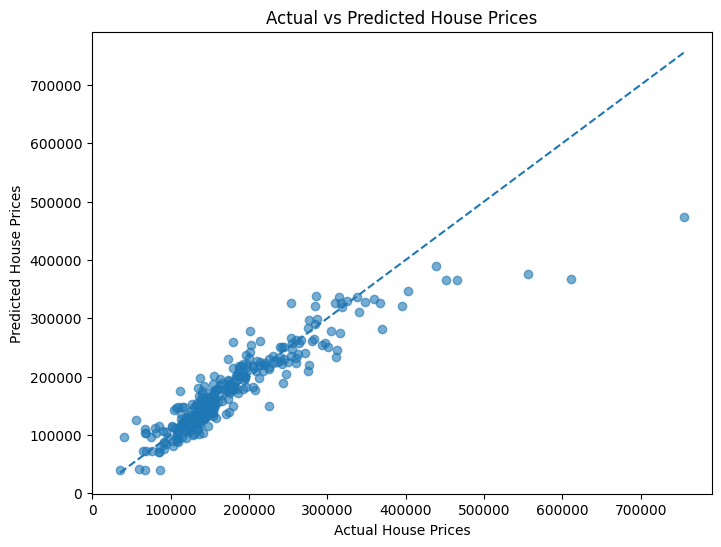

In [47]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.show()

## Actual vs Predicted Price Analysis

The scatter plot compares actual house prices with predicted
house prices generated by the Linear Regression model.

The diagonal reference line represents perfect predictions.

Points closer to the diagonal line indicate more accurate
predictions, while points farther away indicate prediction errors.

This visualization helps us understand the performance
and limitations of our regression model.

In [48]:
residuals = y_test - y_pred
print("First 10 Residual Values:")
print(residuals.head(10))

First 10 Residual Values:
892     17525.641007
1105    -3961.595966
413     -2585.611443
522    -20363.278667
1036    40825.669492
614      3689.382582
218     78284.433794
1160   -17888.734288
649     13191.770792
887      9617.402037
Name: SalePrice, dtype: float64


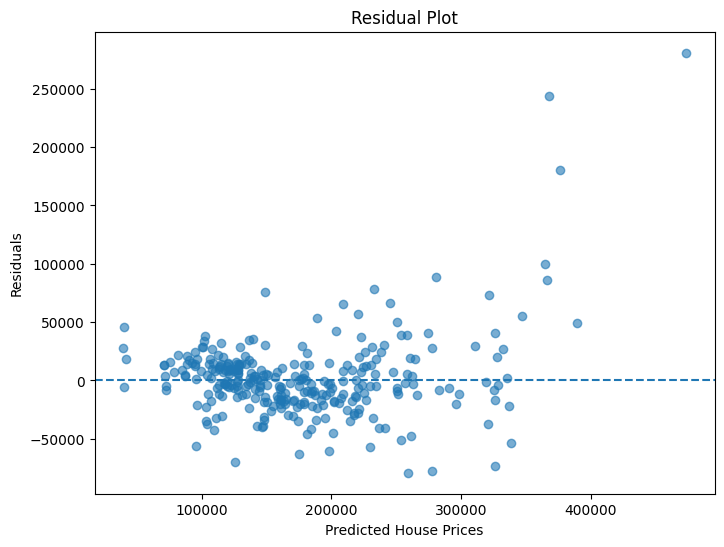

In [49]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)
plt.axhline(
    y=0,
    linestyle='--'
)
plt.title('Residual Plot')
plt.xlabel('Predicted House Prices')
plt.ylabel('Residuals')
plt.show()

## Residual Analysis

Residual analysis helps evaluate the errors made by
the Linear Regression model.

Residuals are calculated by subtracting predicted prices
from actual prices.

A random distribution of residuals around zero suggests
that the model captures the relationship reasonably well.

Systematic patterns may indicate that the model does not
fully capture the underlying relationship.

In [50]:
trained_model = model_pipeline.named_steps['regression']
feature_names = model_pipeline.named_steps[
    'preprocessing'
].get_feature_names_out()
coefficients = trained_model.coef_
coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})
coefficient_df = coefficient_df.sort_values(
    by='Coefficient',
    ascending=False
)
coefficient_df.head(15)

,Feature,Coefficient
23,cat__Neighborhood_NoRidge,43324.816026
24,cat__Neighborhood_NridgHt,42111.341582
30,cat__Neighborhood_StoneBr,39512.231534
14,cat__Neighborhood_Crawfor,26553.795257
32,cat__Neighborhood_Veenker,16416.266970
0,num__OverallQual,15931.772042
3,num__GarageCars,12242.422887
12,cat__Neighborhood_ClearCr,9306.715866
11,cat__Neighborhood_BrkSide,3598.331223
4,num__YearBuilt,394.649222


In [51]:
coefficient_df.tail(15).sort_values(
    by='Coefficient',
    ascending=True
)

,Feature,Coefficient
10,cat__Neighborhood_BrDale,-25853.751016
8,cat__Neighborhood_Blmngtn,-24729.112969
19,cat__Neighborhood_Mitchel,-16726.281089
15,cat__Neighborhood_Edwards,-16008.590348
28,cat__Neighborhood_SawyerW,-15749.655464
16,cat__Neighborhood_Gilbert,-14613.937730
22,cat__Neighborhood_NWAmes,-14390.713369
25,cat__Neighborhood_OldTown,-10079.128003
21,cat__Neighborhood_NPkVill,-9674.340615
18,cat__Neighborhood_MeadowV,-7062.280938


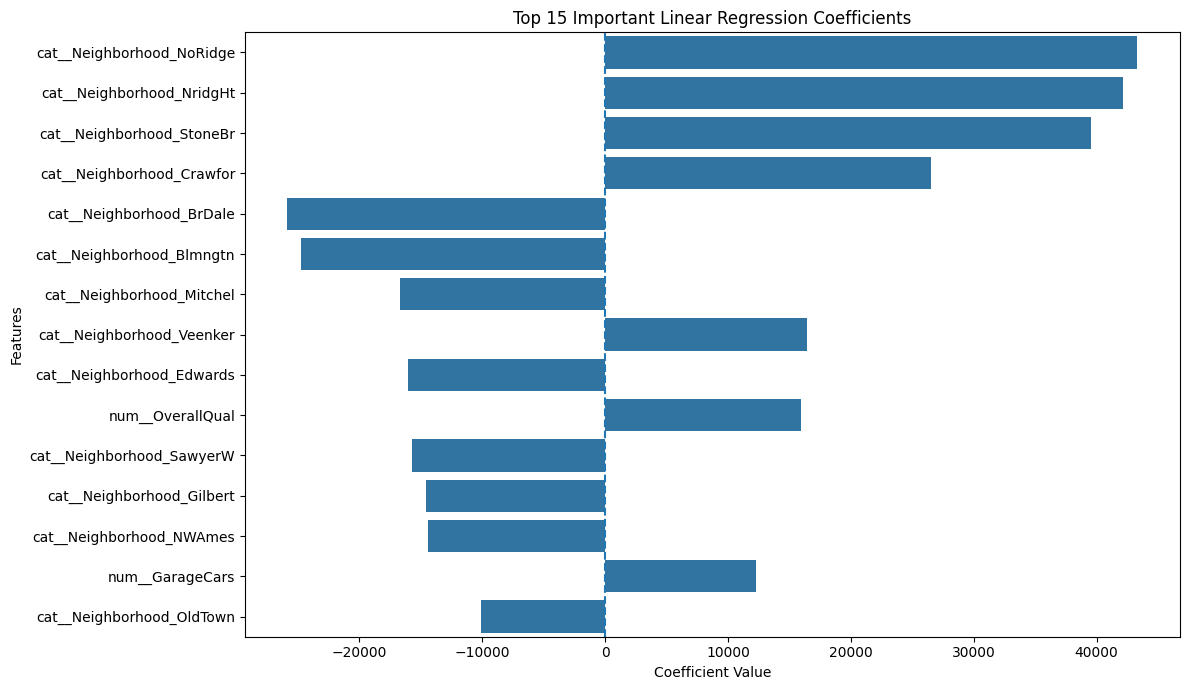

In [52]:
top_coefficients = coefficient_df.reindex(
    coefficient_df['Coefficient'].abs().sort_values(
        ascending=False
    ).head(15).index
)
plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_coefficients,
    x='Coefficient',
    y='Feature'
)
plt.title('Top 15 Important Linear Regression Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.axvline(x=0, linestyle='--')
plt.tight_layout()
plt.show()

## Coefficient Analysis

Coefficient analysis helps us understand how individual
features influence house price predictions.

Positive coefficients indicate that an increase in a feature
is associated with an increase in predicted house prices,
while negative coefficients indicate the opposite.

The magnitude of each coefficient represents the change
in predicted price for a one-unit increase in that feature,
holding other features constant.

Categorical features converted through One-Hot Encoding
represent differences relative to the omitted reference category.

Coefficient values should be interpreted carefully because
features have different units and scales.

In [53]:
ridge_pipeline = Pipeline(steps=[
    ('preprocessing', ColumnTransformer(transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ])),
    ('regression', Ridge(alpha=1.0))
])
ridge_pipeline.fit(X_train, y_train)
ridge_pred = ridge_pipeline.predict(X_test)
print("Ridge Regression training completed!")

Ridge Regression training completed!


In [54]:
lasso_pipeline = Pipeline(steps=[
    ('preprocessing', ColumnTransformer(transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ])),
    ('regression', Lasso(alpha=100.0, max_iter=10000))
])
lasso_pipeline.fit(X_train, y_train)
lasso_pred = lasso_pipeline.predict(X_test)
print("Lasso Regression training completed!")

Lasso Regression training completed!


In [55]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],

    'MSE': [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, ridge_pred),
        mean_squared_error(y_test, lasso_pred)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, lasso_pred))
    ],

    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred)
    ]
})
model_comparison

,Model,MSE,RMSE,R2 Score
0,Linear Regression,1.293988e+09,35972.040649,0.831300
1,Ridge Regression,2.010051e+09,44833.597700,0.737944
2,Lasso Regression,1.285922e+09,35859.760786,0.832351


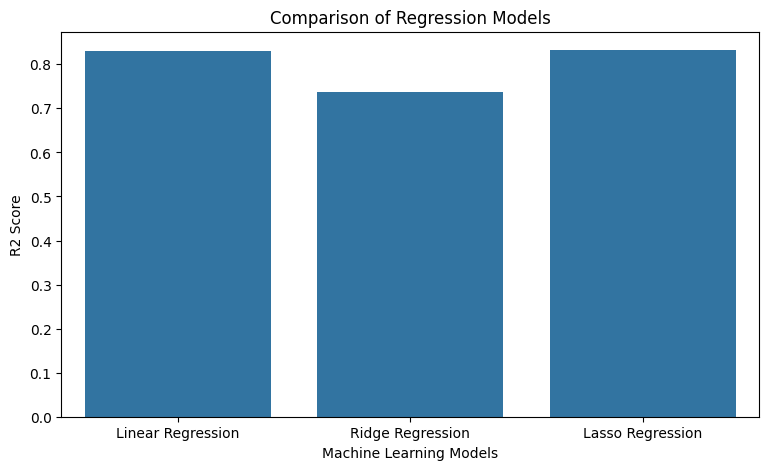

In [56]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=model_comparison,
    x='Model',
    y='R2 Score'
)
plt.title('Comparison of Regression Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score')
plt.show()

## Model Comparison

Three regression algorithms were evaluated:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression

Ridge Regression uses L2 regularization to reduce large
coefficient values.

Lasso Regression uses L1 regularization and can eliminate
less useful features by reducing their coefficients to zero.

The models were compared using MSE, RMSE and R2 Score.

The model with lower error metrics and a higher R2 Score
provides better predictive performance on the test dataset.